<a href="https://colab.research.google.com/github/fboldt/aulasml/blob/master/aula08a_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True)
print(X.shape)
print(set(y))

(569, 30)
{np.int64(0), np.int64(1)}


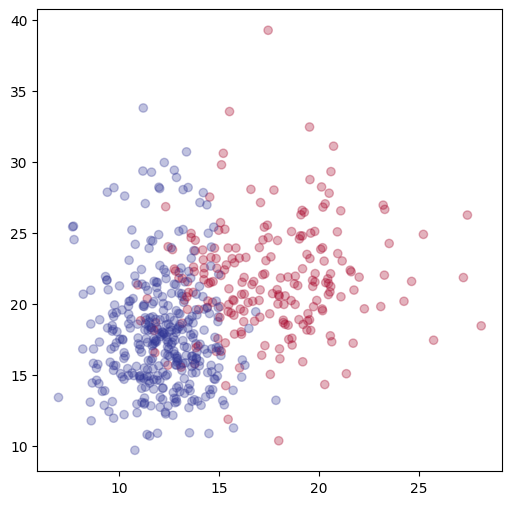

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c=y, cmap=plt.cm.RdYlBu, alpha=0.3)
plt.show()

# Principal Component Analisys (PCA)

In [5]:
from sklearn.decomposition import PCA
pca = PCA(n_components=30)
pca.fit(X)
X_pca = pca.transform(X)
print(X_pca.shape)

(569, 30)


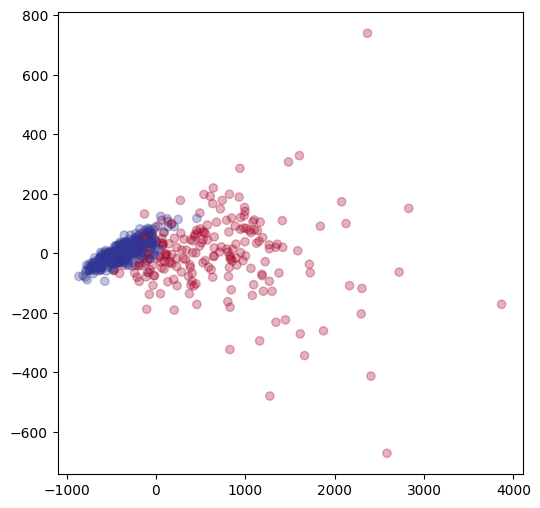

In [6]:
plt.figure(figsize=(6,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap=plt.cm.RdYlBu, alpha=0.3)
plt.show()

In [12]:
print(pca.components_.shape)

(30, 30)


In [10]:
print(pca.explained_variance_)

[4.43782605e+05 7.31010006e+03 7.03833742e+02 5.46487379e+01
 3.98900178e+01 3.00458768e+00 1.81533029e+00 3.71466740e-01
 1.55513547e-01 8.40612196e-02 3.16089532e-02 7.49736506e-03
 3.16165651e-03 2.16150395e-03 1.32653879e-03 6.40269301e-04
 3.74883320e-04 2.35169625e-04 1.84583467e-04 1.64180063e-04
 7.81102006e-05 5.76111659e-05 3.49172775e-05 2.83952688e-05
 1.61463676e-05 1.24902419e-05 3.68048171e-06 2.84790425e-06
 2.00491564e-06 7.01997261e-07]


In [13]:
print(pca.explained_variance_ratio_)

[9.82044672e-01 1.61764899e-02 1.55751075e-03 1.20931964e-04
 8.82724536e-05 6.64883951e-06 4.01713682e-06 8.22017197e-07
 3.44135279e-07 1.86018721e-07 6.99473205e-08 1.65908878e-08
 6.99641648e-09 4.78318305e-09 2.93549213e-09 1.41684926e-09
 8.29577731e-10 5.20405880e-10 4.08463983e-10 3.63313376e-10
 1.72849736e-10 1.27487508e-10 7.72682973e-11 6.28357715e-11
 3.57302295e-11 2.76396041e-11 8.14452259e-12 6.30211541e-12
 4.43666944e-12 1.55344680e-12]


In [14]:
print(pca.explained_variance_ratio_.sum())

0.9999999999999997


In [17]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier

splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
model = RandomForestClassifier()

In [18]:
scores = cross_val_score(model, X, y, scoring='accuracy', cv=splitter, n_jobs=-1)
print('Accuracy: %.3f (%.3f)' % (scores.mean(), scores.std()))

Accuracy: 0.957 (0.021)


In [19]:
scores = cross_val_score(model, X_pca, y, scoring='accuracy', cv=splitter, n_jobs=-1)
print('Accuracy: %.3f (%.3f)' % (scores.mean(), scores.std()))

Accuracy: 0.951 (0.019)


In [20]:
n_most_important_features = 8
scores = cross_val_score(model,
                         X_pca[:,:n_most_important_features], y,
                         scoring='accuracy', cv=splitter, n_jobs=-1)
print('Accuracy: %.3f (%.3f)' % (scores.mean(), scores.std()))

Accuracy: 0.951 (0.018)


In [21]:
print(pca.explained_variance_ratio_[:n_most_important_features].sum())

0.9999993645298417


In [24]:
def compare_model_with_datasets(model, y, X1, X2):
  scores = cross_val_score(model, X1, y, scoring='accuracy', cv=splitter, n_jobs=-1)
  print('Accuracy X1: %.3f (%.3f)' % (scores.mean(), scores.std()))
  scores = cross_val_score(model, X2, y, scoring='accuracy', cv=splitter, n_jobs=-1)
  print('Accuracy X2: %.3f (%.3f)' % (scores.mean(), scores.std()))

compare_model_with_datasets(model, y, X, X_pca[:, :n_most_important_features])

Accuracy X1: 0.960 (0.020)
Accuracy X2: 0.951 (0.018)


In [25]:
from sklearn.neighbors import KNeighborsClassifier
compare_model_with_datasets(KNeighborsClassifier(),
                            y, X, X_pca[:, :n_most_important_features])

Accuracy X1: 0.930 (0.016)
Accuracy X2: 0.930 (0.016)


In [26]:
from sklearn.linear_model import LogisticRegression
compare_model_with_datasets(LogisticRegression(),
                            y, X, X_pca[:, :n_most_important_features])

Accuracy X1: 0.946 (0.018)
Accuracy X2: 0.942 (0.018)


In [27]:
from sklearn.naive_bayes import GaussianNB
compare_model_with_datasets(GaussianNB(),
                            y, X, X_pca[:, :n_most_important_features])

Accuracy X1: 0.939 (0.017)
Accuracy X2: 0.905 (0.028)


In [28]:
pca = PCA(n_components=0.9999)
pca.fit(X)
X_pca = pca.transform(X)
print(X_pca.shape)

(569, 5)


In [30]:
from sklearn.pipeline import make_pipeline
model = make_pipeline(PCA(n_components=0.9999),
                      RandomForestClassifier())
scores = cross_val_score(model, X, y, scoring='accuracy', cv=splitter, n_jobs=-1)
print('Accuracy: %.3f (%.3f)' % (scores.mean(), scores.std()))

Accuracy: 0.953 (0.019)


# PCA fail

In [37]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=100,
                  centers=[
                      [0.1, 0.1], [0.1, 0.4],
                      [0.2, 0.1], [0.2, 0.4],
                      [0.3, 0.1], [0.3, 0.4],
                      [0.4, 0.1], [0.4, 0.4],
                      [0.5, 0.1], [0.5, 0.4],
                      [0.6, 0.1], [0.6, 0.4],
                      [0.7, 0.1], [0.7, 0.4],
                      [0.8, 0.1], [0.8, 0.4],
                      [0.9, 0.1], [0.9, 0.4],
                      [1.0, 0.1], [1.0, 0.4]
                  ],
                  n_features=2,
                  cluster_std=0.07,
                  random_state=42)
y = y % 2
print(X.shape)

(100, 2)


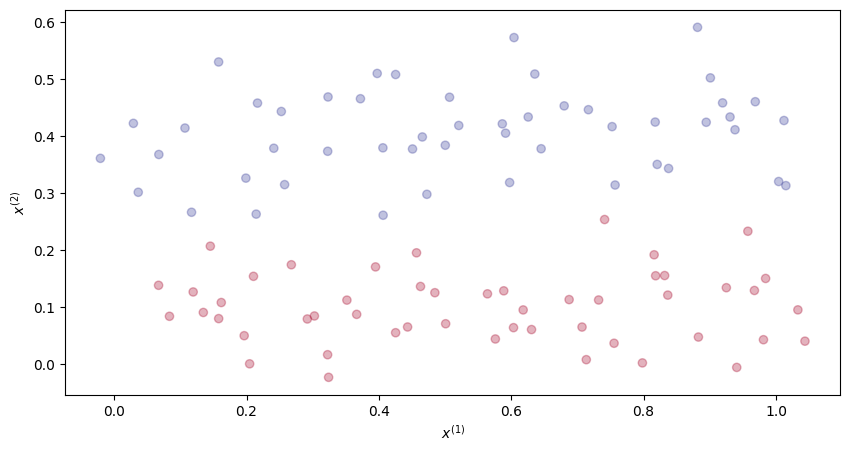

In [40]:
plt.figure(figsize=(10, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.xlabel('$x^{(1)}$')
plt.ylabel('$x^{(2)}$')
plt.show()

In [43]:
model = LogisticRegression()
scores = cross_val_score(model, X, y, scoring='accuracy', cv=splitter, n_jobs=-1)
print('Accuracy: %.3f (%.3f)' % (scores.mean(), scores.std()))

Accuracy: 0.990 (0.027)


In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

1.0


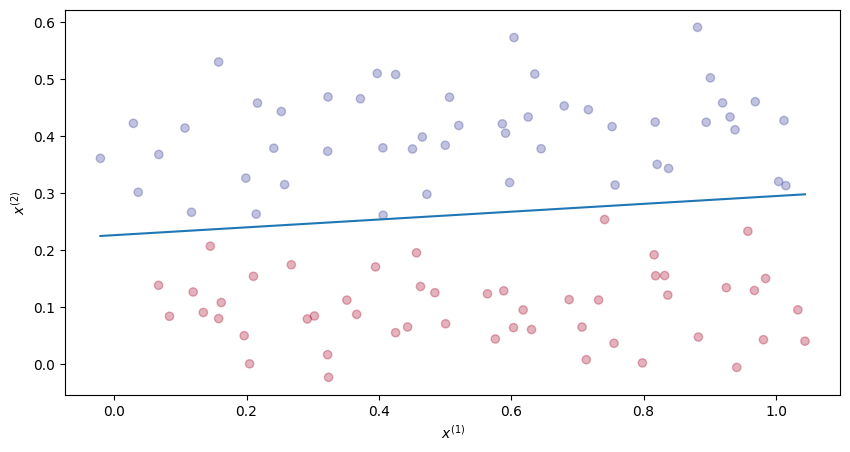

In [48]:
import numpy as np
def plot_hyperplan(model, X, y):
  xs = np.array([X[:, 0].min(), X[:, 0].max()])
  vector = model.coef_[0]
  bias = model.intercept_
  ys = (-vector[0] * xs - bias) / vector[1]
  plt.figure(figsize=(10, 5))
  plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.3, cmap=plt.cm.RdYlBu)
  plt.xlabel('$x^{(1)}$')
  plt.ylabel('$x^{(2)}$')
  plt.plot(xs, ys)
  plt.show()

plot_hyperplan(model, X, y)

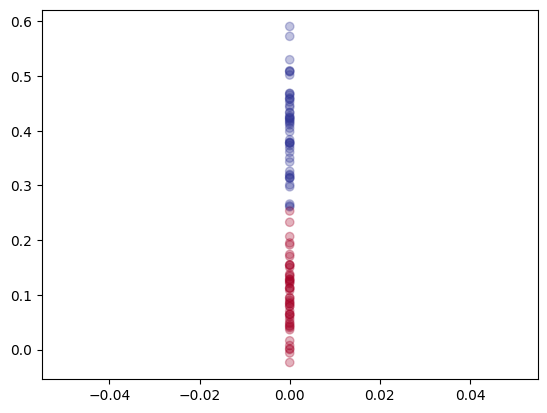

In [49]:
plt.scatter(np.zeros(X.shape[0]), X[:, 1], c=y, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.show()

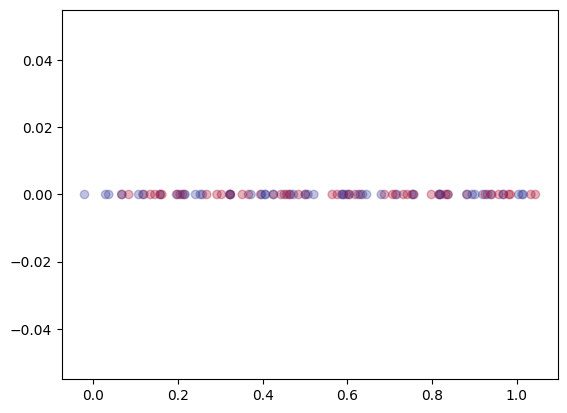

In [53]:
plt.scatter(X[:, 0], np.zeros(X.shape[0]), c=y, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.show()

In [63]:
pca = PCA(n_components=1)
X_train_pca = pca.fit_transform(X_train)
print(X_pca.shape)

model.fit(X_train_pca, y_train)

X_test_pca = pca.transform(X_test)
print(model.score(X_test_pca, y_test))

(100, 1)
0.45


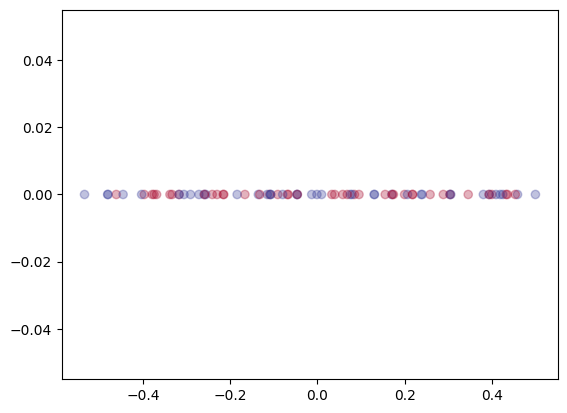

In [66]:
plt.scatter(X_train_pca[:, 0], np.zeros(X_train_pca.shape[0]),
            c=y_train, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.show()

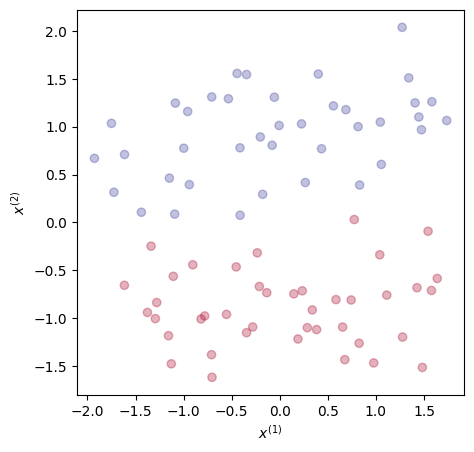

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
plt.figure(figsize=(5, 5))
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1],
            c=y_train, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.xlabel('$x^{(1)}$')
plt.ylabel('$x^{(2)}$')
plt.show()

In [70]:
pca = PCA(n_components=1)
X_train_pca = pca.fit_transform(X_train_scaled)
model.fit(X_train_pca, y_train)

X_test_scaled = scaler.transform(X_test)
X_test_pca = pca.transform(X_test_scaled)
print(model.score(X_test_pca, y_test))

0.7


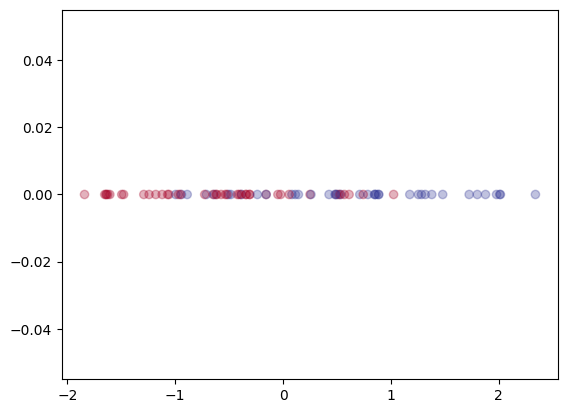

In [71]:
plt.scatter(X_train_pca[:, 0], np.zeros(X_train_pca.shape[0]),
            c=y_train, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.show()